In [1]:
!pip install -q opencv-python-headless scikit-learn tqdm pandas matplotlib

In [1]:
import os
import cv2
import csv
import random
import shutil
import subprocess
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

## Configure your AWS paths

In [2]:
# ============================================================
# AWS / DATASET CONFIGURATION
# ============================================================

# S3 locations
BUCKET = "YOUR-BUCKET-NAME"
S3_SOURCE = "raw/asl_alphabet_train/"
S3_OUTPUT = "processed/"


# Reproducibility
RANDOM_SEED = 42

# Dataset split
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

# Gaussian filtering
GAUSSIAN_KERNEL = (5, 5)
GAUSSIAN_SIGMA = 1.0

# Canny edge detection
CANNY_LOW = 100
CANNY_HIGH = 200

# Accepted image formats
VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}



In [3]:
# ============================================================
# LOCAL SAGEMAKER PATHS
# ============================================================

BASE_DIR = Path.cwd()

LOCAL_SOURCE = (
    BASE_DIR / "asl_alphabet_train"
)

LOCAL_OUTPUT = (
    BASE_DIR / "asl_preprocessed"
)

LOCAL_SOURCE.mkdir(
    parents=True,
    exist_ok=True
)

LOCAL_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

print("Current working directory:")
print(BASE_DIR)

print("\nDataset location:")
print(LOCAL_SOURCE)

print("\nPreprocessing output:")
print(LOCAL_OUTPUT)

Current working directory:
/home/ec2-user/SageMaker

Dataset location:
/home/ec2-user/SageMaker/asl_alphabet_train

Preprocessing output:
/home/ec2-user/SageMaker/asl_preprocessed


## Check the SageMaker environment

In [4]:
import shutil

disk = shutil.disk_usage(BASE_DIR)

print("\nDisk space:")
print(f"Total: {disk.total / (1024**3):.2f} GB")
print(f"Free:  {disk.free / (1024**3):.2f} GB")


Disk space:
Total: 48.91 GB
Free:  45.21 GB


## Download the dataset from S3

In [5]:
import boto3

s3 = boto3.client("s3")

response = s3.list_objects_v2(
    Bucket=BUCKET,
    Prefix=S3_SOURCE,
    MaxKeys=5
)

for obj in response.get("Contents", []):
    print(obj["Key"])

raw/asl_alphabet_train/A/A1.jpg
raw/asl_alphabet_train/A/A10.jpg
raw/asl_alphabet_train/A/A100.jpg
raw/asl_alphabet_train/A/A1000.jpg
raw/asl_alphabet_train/A/A1001.jpg


In [10]:
command = [
    "aws",
    "s3",
    "sync",
    f"s3://{BUCKET}/{S3_SOURCE}",
    str(LOCAL_SOURCE)
]

print("Downloading dataset from S3...")
subprocess.run(command, check=True)

print("Download completed.")

Download completed.


## Verify the dataset

In [6]:
image_paths = [
    p
    for p in LOCAL_SOURCE.rglob("*")
    if p.is_file()
    and p.suffix.lower() in VALID_EXTENSIONS
]

print(f"Images found: {len(image_paths)}")

Images found: 87000


In [7]:
class_dirs = sorted(
    p for p in LOCAL_SOURCE.iterdir()
    if p.is_dir()
)

print("Number of classes:", len(class_dirs))

print("\nClasses:")
for directory in class_dirs:
    print(directory.name)

Number of classes: 29

Classes:
A
B
C
D
E
F
G
H
I
J
K
L
M
N
O
P
Q
R
S
T
U
V
W
X
Y
Z
del
nothing
space


## Check image dimensions before processing

In [8]:
random.seed(RANDOM_SEED)

sample_paths = random.sample(
    image_paths,
    min(100, len(image_paths))
)

dimensions = Counter()
channels = Counter()

for image_path in tqdm(sample_paths):
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if image is None:
        continue

    height, width = image.shape[:2]

    if len(image.shape) == 2:
        channel_count = 1
    else:
        channel_count = image.shape[2]

    dimensions[(height, width)] += 1
    channels[channel_count] += 1

print("Dimensions:")
for dimension, count in dimensions.items():
    print(dimension, ":", count)

print("\nChannels:")
for channel, count in channels.items():
    print(channel, ":", count)

  0%|          | 0/100 [00:00<?, ?it/s]

Dimensions:
(200, 200) : 100

Channels:
3 : 100


## Create the train/validation/test split

In [9]:
records = []

for class_dir in class_dirs:

    label = class_dir.name

    class_images = [
        p
        for p in class_dir.iterdir()
        if p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    ]

    for image_path in class_images:

        records.append({
            "path": image_path,
            "label": label
        })

print("Total records:", len(records))

Total records: 87000


In [10]:
# ------------------------------------------------------------
# First split: 85% train/validation, 15% test
# ------------------------------------------------------------

train_val, test_records = train_test_split(
    records,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=[
        record["label"]
        for record in records
    ]
)

# ------------------------------------------------------------
# Second split:
# validation = 15% of the TOTAL dataset
# ------------------------------------------------------------

relative_validation_size = (
    VALIDATION_SIZE /
    (1 - TEST_SIZE)
)

train_records, validation_records = train_test_split(
    train_val,
    test_size=relative_validation_size,
    random_state=RANDOM_SEED,
    stratify=[
        record["label"]
        for record in train_val
    ]
)

splits = {
    "train": train_records,
    "validation": validation_records,
    "test": test_records
}

print("\nSplit sizes:")

for split_name, split_records in splits.items():
    print(
        f"{split_name:12} "
        f"{len(split_records):,} images"
    )


Split sizes:
train        60,900 images
validation   13,050 images
test         13,050 images


## Verify class balance

In [11]:
for split_name, split_records in splits.items():

    counts = Counter(
        record["label"]
        for record in split_records
    )

    print("\n" + "=" * 50)
    print(split_name.upper())
    print("=" * 50)

    print("Number of classes:", len(counts))

    print(
        "Minimum class count:",
        min(counts.values())
    )

    print(
        "Maximum class count:",
        max(counts.values())
    )


TRAIN
Number of classes: 29
Minimum class count: 2100
Maximum class count: 2100

VALIDATION
Number of classes: 29
Minimum class count: 450
Maximum class count: 450

TEST
Number of classes: 29
Minimum class count: 450
Maximum class count: 450


## Create the preprocessing function

In [12]:
def process_image(image_path):

    # --------------------------------------------------------
    # Read original RGB image
    # OpenCV internally stores it as BGR.
    # --------------------------------------------------------

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise ValueError(
            f"Could not read image: {image_path}"
        )

    # --------------------------------------------------------
    # Gaussian filtering
    # --------------------------------------------------------

    filtered = cv2.GaussianBlur(
        image,
        GAUSSIAN_KERNEL,
        sigmaX=GAUSSIAN_SIGMA
    )

    # --------------------------------------------------------
    # Convert to grayscale for Canny
    # --------------------------------------------------------

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # --------------------------------------------------------
    # Canny edge detection
    # --------------------------------------------------------

    edges = cv2.Canny(
        gray,
        threshold1=CANNY_LOW,
        threshold2=CANNY_HIGH
    )

    return filtered, edges

## Test the processing on ONE image

In [13]:
test_image_path = records[0]["path"]

filtered, edges = process_image(
    test_image_path
)

original = cv2.imread(
    str(test_image_path),
    cv2.IMREAD_COLOR
)

print("Original shape:", original.shape)
print("Filtered shape:", filtered.shape)
print("Edges shape:", edges.shape)

print("\nOriginal channels:", original.shape[2])
print("Filtered channels:", filtered.shape[2])
print("Edges channels: 1")

Original shape: (200, 200, 3)
Filtered shape: (200, 200, 3)
Edges shape: (200, 200)

Original channels: 3
Filtered channels: 3
Edges channels: 1


## Visually inspect ONE image

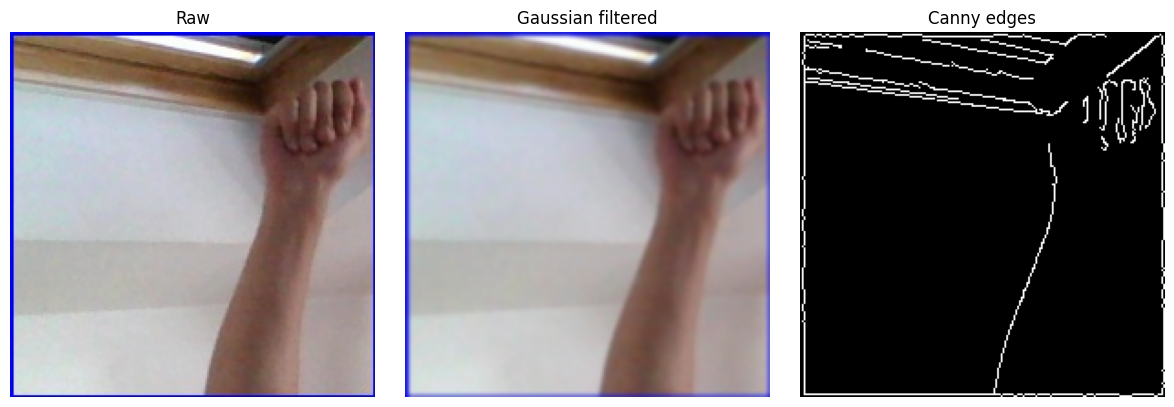

In [14]:
original_rgb = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)

filtered_rgb = cv2.cvtColor(
    filtered,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Raw")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(filtered_rgb)
plt.title("Gaussian filtered")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny edges")
plt.axis("off")

plt.tight_layout()
plt.show()

## Create output directories

In [15]:
for representation in ["filtered", "edges"]:

    for split_name in splits:

        for class_dir in class_dirs:

            output_dir = (
                LOCAL_OUTPUT
                / representation
                / split_name
                / class_dir.name
            )

            output_dir.mkdir(
                parents=True,
                exist_ok=True
            )

print("Output directories created.")

Output directories created.


## Run a 100-image test

In [16]:
TEST_RUN_SIZE = 100

random.seed(RANDOM_SEED)

test_records_small = random.sample(
    records,
    min(TEST_RUN_SIZE, len(records))
)

test_output = (
    LOCAL_OUTPUT / "test_run"
)

test_output.mkdir(
    parents=True,
    exist_ok=True
)

successful = 0
failed = []

for record in tqdm(
    test_records_small,
    desc="Test preprocessing"
):

    try:

        filtered, edges = process_image(
            record["path"]
        )

        label = record["label"]
        filename = record["path"].name

        filtered_path = (
            test_output
            / "filtered"
            / label
            / filename
        )

        edge_path = (
            test_output
            / "edges"
            / label
            / f"{record['path'].stem}.png"
        )

        filtered_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        edge_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        cv2.imwrite(
            str(filtered_path),
            filtered
        )

        cv2.imwrite(
            str(edge_path),
            edges
        )

        successful += 1

    except Exception as error:

        failed.append({
            "path": str(record["path"]),
            "error": str(error)
        })

print("\nTest run completed.")
print("Successful:", successful)
print("Failed:", len(failed))

Test preprocessing:   0%|          | 0/100 [00:00<?, ?it/s]


Test run completed.
Successful: 100
Failed: 0


## Verify the 100-image test

In [17]:
test_filtered = list(
    (test_output / "filtered").rglob("*")
)

test_edges = list(
    (test_output / "edges").rglob("*")
)

test_filtered = [
    p for p in test_filtered
    if p.is_file()
]

test_edges = [
    p for p in test_edges
    if p.is_file()
]

print("Filtered files:", len(test_filtered))
print("Edge files:", len(test_edges))

Filtered files: 100
Edge files: 100


## Check the generated test images

In [18]:
sample_filtered = test_filtered[0]
sample_edge = test_edges[0]

filtered_test_image = cv2.imread(
    str(sample_filtered),
    cv2.IMREAD_COLOR
)

edge_test_image = cv2.imread(
    str(sample_edge),
    cv2.IMREAD_GRAYSCALE
)

print("Filtered:")
print("  Shape:", filtered_test_image.shape)
print("  Channels:", filtered_test_image.shape[2])

print("\nEdges:")
print("  Shape:", edge_test_image.shape)
print("  Channels: 1")

Filtered:
  Shape: (200, 200, 3)
  Channels: 3

Edges:
  Shape: (200, 200)
  Channels: 1


## Check disk space before the full run

In [20]:

disk = shutil.disk_usage(BASE_DIR)

print("\nDisk space:")
print(f"Total: {disk.total / (1024**3):.2f} GB")
print(f"Free:  {disk.free / (1024**3):.2f} GB")


Disk space:
Total: 48.91 GB
Free:  45.21 GB


## Full preprocessing

In [21]:
# ============================================================
# FULL DATASET PREPROCESSING
# ============================================================

manifest_path = (
    LOCAL_OUTPUT / "manifest.csv"
)

manifest_file = open(
    manifest_path,
    "w",
    newline="",
    encoding="utf-8"
)

writer = csv.DictWriter(
    manifest_file,
    fieldnames=[
        "split",
        "label",
        "original_path",
        "filtered_path",
        "edge_path"
    ]
)

writer.writeheader()

successful = 0
failed = []

for split_name, split_records in splits.items():

    print(
        f"\nProcessing {split_name.upper()} "
        f"({len(split_records):,} images)"
    )

    for record in tqdm(
        split_records,
        desc=split_name
    ):

        try:

            source_path = record["path"]
            label = record["label"]

            # -----------------------------------------------
            # Process
            # -----------------------------------------------

            filtered, edges = process_image(
                source_path
            )

            # -----------------------------------------------
            # Output paths
            # -----------------------------------------------

            filtered_path = (
                LOCAL_OUTPUT
                / "filtered"
                / split_name
                / label
                / source_path.name
            )

            edge_path = (
                LOCAL_OUTPUT
                / "edges"
                / split_name
                / label
                / f"{source_path.stem}.png"
            )

            filtered_path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            edge_path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            # -----------------------------------------------
            # Save
            # -----------------------------------------------

            success_filtered = cv2.imwrite(
                str(filtered_path),
                filtered
            )

            success_edges = cv2.imwrite(
                str(edge_path),
                edges
            )

            if not success_filtered:
                raise IOError(
                    f"Failed to save {filtered_path}"
                )

            if not success_edges:
                raise IOError(
                    f"Failed to save {edge_path}"
                )

            # -----------------------------------------------
            # Manifest
            # -----------------------------------------------

            writer.writerow({
                "split": split_name,
                "label": label,
                "original_path": str(source_path),
                "filtered_path": str(filtered_path),
                "edge_path": str(edge_path)
            })

            successful += 1

        except Exception as error:

            failed.append({
                "path": str(record["path"]),
                "split": split_name,
                "label": record["label"],
                "error": str(error)
            })

manifest_file.close()

print("\n" + "=" * 60)
print("FULL PREPROCESSING COMPLETE")
print("=" * 60)

print("Successful:", successful)
print("Failed:", len(failed))

if failed:
    print("\nFirst five failures:")
    for failure in failed[:5]:
        print(failure)


Processing TRAIN (60,900 images)


train:   0%|          | 0/60900 [00:00<?, ?it/s]


Processing VALIDATION (13,050 images)


validation:   0%|          | 0/13050 [00:00<?, ?it/s]


Processing TEST (13,050 images)


test:   0%|          | 0/13050 [00:00<?, ?it/s]


FULL PREPROCESSING COMPLETE
Successful: 87000
Failed: 0


## Verify the complete output

In [22]:
print("Expected records:", len(records))
print("Successful:", successful)
print("Failed:", len(failed))

assert successful == len(records), (
    f"Expected {len(records)} successful images, "
    f"but processed {successful}."
)

print("\nAll images processed successfully.")

Expected records: 87000
Successful: 87000
Failed: 0

All images processed successfully.


## Verify the manifest

In [23]:
manifest = pd.read_csv(
    LOCAL_OUTPUT / "manifest.csv"
)

print("Manifest rows:", len(manifest))

print("\nColumns:")
print(list(manifest.columns))

print("\nSplit counts:")
print(
    manifest["split"].value_counts()
)

print("\nClass counts:")
print(
    manifest["label"].value_counts().sort_index()
)

Manifest rows: 87000

Columns:
['split', 'label', 'original_path', 'filtered_path', 'edge_path']

Split counts:
split
train         60900
validation    13050
test          13050
Name: count, dtype: int64

Class counts:
label
A          3000
B          3000
C          3000
D          3000
E          3000
F          3000
G          3000
H          3000
I          3000
J          3000
K          3000
L          3000
M          3000
N          3000
O          3000
P          3000
Q          3000
R          3000
S          3000
T          3000
U          3000
V          3000
W          3000
X          3000
Y          3000
Z          3000
del        3000
nothing    3000
space      3000
Name: count, dtype: int64


## Verify every generated file exists

In [24]:
missing_filtered = []
missing_edges = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Checking files"
):

    if not Path(row["filtered_path"]).is_file():
        missing_filtered.append(
            row["filtered_path"]
        )

    if not Path(row["edge_path"]).is_file():
        missing_edges.append(
            row["edge_path"]
        )

print(
    "Missing filtered images:",
    len(missing_filtered)
)

print(
    "Missing edge images:",
    len(missing_edges)
)

Checking files:   0%|          | 0/87000 [00:00<?, ?it/s]

Missing filtered images: 0
Missing edge images: 0


## Verify channels across the dataset

In [25]:
def inspect_representation(
    version,
    split="train",
    sample_size=100
):

    if version == "filtered":

        directory = (
            LOCAL_OUTPUT
            / "filtered"
            / split
        )

        read_mode = cv2.IMREAD_COLOR

    elif version == "edges":

        directory = (
            LOCAL_OUTPUT
            / "edges"
            / split
        )

        read_mode = cv2.IMREAD_GRAYSCALE

    else:
        raise ValueError(
            "Version must be 'filtered' or 'edges'"
        )

    paths = [
        p for p in directory.rglob("*")
        if p.is_file()
    ]

    random.seed(RANDOM_SEED)

    sample = random.sample(
        paths,
        min(sample_size, len(paths))
    )

    shapes = Counter()
    dtypes = Counter()

    for path in sample:

        image = cv2.imread(
            str(path),
            read_mode
        )

        shapes[image.shape] += 1
        dtypes[str(image.dtype)] += 1

    return shapes, dtypes

In [26]:
filtered_shapes, filtered_dtypes = (
    inspect_representation("filtered")
)

edge_shapes, edge_dtypes = (
    inspect_representation("edges")
)

print("FILTERED")
print("Shapes:", filtered_shapes)
print("Data types:", filtered_dtypes)

print("\nEDGES")
print("Shapes:", edge_shapes)
print("Data types:", edge_dtypes)

FILTERED
Shapes: Counter({(200, 200, 3): 100})
Data types: Counter({'uint8': 100})

EDGES
Shapes: Counter({(200, 200): 100})
Data types: Counter({'uint8': 100})


## Generate the final comparison image

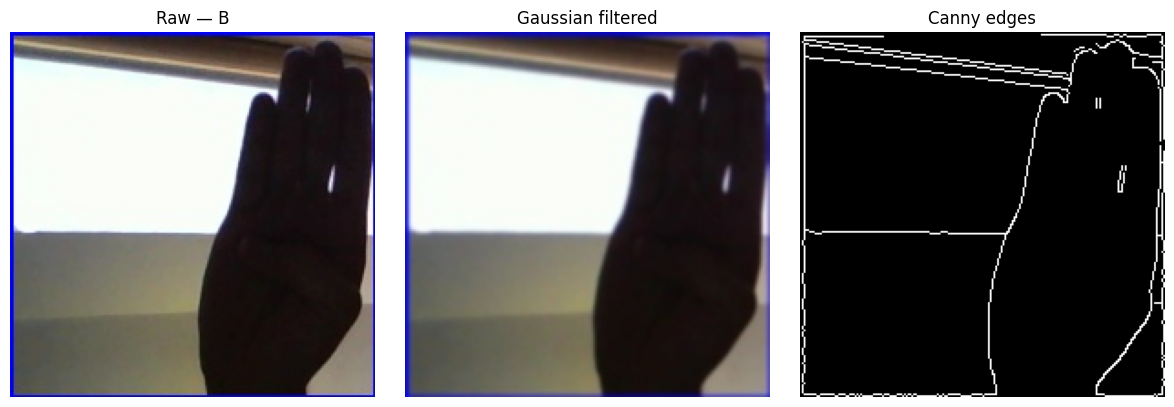

Saved: /home/ec2-user/SageMaker/asl_preprocessed/preprocessing_comparison.png


In [27]:
example = manifest.iloc[0]

original = cv2.imread(
    example["original_path"],
    cv2.IMREAD_COLOR
)

filtered = cv2.imread(
    example["filtered_path"],
    cv2.IMREAD_COLOR
)

edges = cv2.imread(
    example["edge_path"],
    cv2.IMREAD_GRAYSCALE
)

original_rgb = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)

filtered_rgb = cv2.cvtColor(
    filtered,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title(
    f"Raw — {example['label']}"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(filtered_rgb)
plt.title("Gaussian filtered")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny edges")
plt.axis("off")

plt.tight_layout()

comparison_path = (
    LOCAL_OUTPUT /
    "preprocessing_comparison.png"
)

plt.savefig(
    comparison_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    comparison_path
)

## Upload everything to S3

In [31]:
command = [
    "aws",
    "s3",
    "sync",
    str(LOCAL_OUTPUT),
    f"s3://{BUCKET}/{S3_OUTPUT}"
]

print("Uploading processed dataset to S3...")

subprocess.run(
    command,
    check=True,
    stdout=subprocess.DEVNULL
)

print("Upload completed.")

Uploading processed dataset to S3...
Upload completed.


## FINAL DATASET VERIFICATION

In [33]:
# ============================================================
# FINAL DATASET VERIFICATION
# ============================================================
# Checks:
#   1. Raw images from the original dataset
#   2. Filtered images from preprocessing
#   3. Edge-detected images from preprocessing
#   4. Image dimensions
#   5. Number of channels
#   6. Data types
#   7. Train / validation / test split sizes
#   8. Neural-network input shapes
#
# IMPORTANT:
# Raw images remain in asl_alphabet_train.
# Filtered and edge images are stored in asl_preprocessed.
# ============================================================

import cv2
from pathlib import Path
from collections import Counter
import random
import pandas as pd


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

BASE_DIR = Path("/home/ec2-user/SageMaker")

# Original raw dataset
RAW_DIR = BASE_DIR / "asl_alphabet_train"

# Preprocessed dataset
PREPROCESSED_DIR = BASE_DIR / "asl_preprocessed"

# Manifest generated during preprocessing
MANIFEST_PATH = PREPROCESSED_DIR / "manifest.csv"

SPLITS = ["train", "validation", "test"]

VERSIONS = ["raw", "filtered", "edges"]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}

SAMPLE_SIZE = 100

random.seed(42)


# ============================================================
# 2. CHECK THAT MAIN DIRECTORIES EXIST
# ============================================================

print("=" * 75)
print("DATASET LOCATION CHECK")
print("=" * 75)

print(f"\nCurrent working directory:")
print(Path.cwd())

print(f"\nRaw dataset:")
print(RAW_DIR)

print(f"\nPreprocessing output:")
print(PREPROCESSED_DIR)

print("\nDirectory status:")

print(
    f"  Raw dataset exists:          "
    f"{RAW_DIR.exists()}"
)

print(
    f"  Preprocessed directory:      "
    f"{PREPROCESSED_DIR.exists()}"
)

print(
    f"  Manifest exists:             "
    f"{MANIFEST_PATH.exists()}"
)


# ============================================================
# 3. FIND RAW DATASET IMAGES
# ============================================================

def get_raw_images():
    """
    Find all original images in the raw dataset.
    The original dataset is organised by class folders.
    """

    if not RAW_DIR.exists():
        return []

    return [
        p
        for p in RAW_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]


raw_images = get_raw_images()

print("\n" + "=" * 75)
print("RAW DATASET")
print("=" * 75)

print(f"Total raw images found: {len(raw_images):,}")


# ============================================================
# 4. LOAD MANIFEST
# ============================================================
# The manifest tells us which images belong to train,
# validation and test.
#
# This is important because the raw images themselves are
# NOT physically copied into asl_preprocessed/raw/.
# ============================================================

if MANIFEST_PATH.exists():

    manifest = pd.read_csv(MANIFEST_PATH)

    print("\nManifest loaded successfully.")

    print(f"Manifest rows: {len(manifest):,}")

    print("\nManifest columns:")
    print(list(manifest.columns))

    print("\nSplit distribution:")
    print(
        manifest["split"]
        .value_counts()
        .sort_index()
    )

else:

    manifest = None

    print(
        "\nWARNING: manifest.csv was not found."
    )

    print(
        "The raw train/validation/test split "
        "cannot be verified from the manifest."
    )


# ============================================================
# 5. FIND PREPROCESSED IMAGES
# ============================================================

def get_preprocessed_images(version, split):
    """
    Find filtered or edge images for a particular split.
    """

    folder = (
        PREPROCESSED_DIR
        / version
        / split
    )

    if not folder.exists():

        print(
            f"WARNING: Folder not found: {folder}"
        )

        return []

    return [
        p
        for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]


# ============================================================
# 6. IMAGE INSPECTION FUNCTION
# ============================================================

def inspect_image(image_path, version):
    """
    Read an image and return its dimensions,
    channels, data type and pixel range.
    """

    if version == "edges":

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

    else:

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR
        )

    if image is None:
        raise ValueError(
            f"Could not read image: {image_path}"
        )

    height, width = image.shape[:2]

    if len(image.shape) == 2:

        channels = 1

    else:

        channels = image.shape[2]

    return {
        "height": height,
        "width": width,
        "channels": channels,
        "dtype": str(image.dtype),
        "min": int(image.min()),
        "max": int(image.max()),
        "shape": image.shape
    }


# ============================================================
# 7. INSPECT FILTERED AND EDGE DATA
# ============================================================

results = {}

for version in ["filtered", "edges"]:

    results[version] = {}

    print("\n")
    print("=" * 75)
    print(f"{version.upper()} DATA")
    print("=" * 75)

    for split in SPLITS:

        image_paths = get_preprocessed_images(
            version,
            split
        )

        if len(image_paths) == 0:

            print(
                f"\n{split.upper()}: "
                f"No images found."
            )

            continue

        sample = random.sample(
            image_paths,
            min(SAMPLE_SIZE, len(image_paths))
        )

        image_info = []

        for path in sample:

            try:

                info = inspect_image(
                    path,
                    version
                )

                image_info.append(info)

            except Exception as e:

                print(
                    f"Could not inspect {path}: {e}"
                )

        results[version][split] = image_info

        shapes = Counter(
            item["shape"]
            for item in image_info
        )

        channels = Counter(
            item["channels"]
            for item in image_info
        )

        dtypes = Counter(
            item["dtype"]
            for item in image_info
        )

        min_values = [
            item["min"]
            for item in image_info
        ]

        max_values = [
            item["max"]
            for item in image_info
        ]

        print(f"\nSplit: {split}")

        print(
            f"Total images available: "
            f"{len(image_paths):,}"
        )

        print(
            f"Images inspected: "
            f"{len(image_info)}"
        )

        print("Shapes:")

        for shape, count in shapes.items():

            print(
                f"  {shape}: {count}"
            )

        print("Channels:")

        for channel_count, count in channels.items():

            print(
                f"  {channel_count} channel(s): "
                f"{count}"
            )

        print("Data types:")

        for dtype, count in dtypes.items():

            print(
                f"  {dtype}: {count}"
            )

        if min_values and max_values:

            print(
                f"Pixel-value range: "
                f"{min(min_values)} - "
                f"{max(max_values)}"
            )


# ============================================================
# 8. DATASET SPLIT SUMMARY
# ============================================================

print("\n")
print("=" * 75)
print("TRAIN / VALIDATION / TEST SPLIT SUMMARY")
print("=" * 75)


if manifest is not None:

    split_counts = (
        manifest["split"]
        .value_counts()
        .reindex(SPLITS)
        .fillna(0)
        .astype(int)
    )

    total = split_counts.sum()

    for split in SPLITS:

        count = split_counts[split]

        percentage = (
            count / total * 100
            if total > 0
            else 0
        )

        print(
            f"{split.capitalize():<12}: "
            f"{count:>6,} images "
            f"({percentage:5.2f}%)"
        )

    print(
        f"{'Total':<12}: "
        f"{total:>6,} images"
    )

else:

    print(
        "Split information unavailable "
        "because manifest.csv was not found."
    )


# ============================================================
# 9. PREPROCESSED IMAGE COUNTS
# ============================================================

print("\n")
print("=" * 75)
print("PREPROCESSED IMAGE COUNTS")
print("=" * 75)

for version in ["filtered", "edges"]:

    print(f"\n{version.upper()}")

    for split in SPLITS:

        paths = get_preprocessed_images(
            version,
            split
        )

        print(
            f"  {split.capitalize():<12}: "
            f"{len(paths):>6,}"
        )


# ============================================================
# 10. CHANNEL COMPARISON
# ============================================================

print("\n")
print("=" * 75)
print("CHANNEL COMPARISON")
print("=" * 75)

expected_channels = {
    "raw": 3,
    "filtered": 3,
    "edges": 1
}


# Raw sample
if raw_images:

    raw_sample = random.sample(
        raw_images,
        min(SAMPLE_SIZE, len(raw_images))
    )

    raw_info = [
        inspect_image(path, "raw")
        for path in raw_sample
    ]

    raw_channels = Counter(
        item["channels"]
        for item in raw_info
    )

    raw_most_common = (
        raw_channels
        .most_common(1)[0][0]
    )

    print(
        f"Raw       : "
        f"{raw_most_common} channel(s)"
    )

else:

    raw_most_common = None

    print("Raw       : No images found.")


# Filtered and edges
for version in ["filtered", "edges"]:

    if (
        "train" not in results[version]
        or not results[version]["train"]
    ):

        print(
            f"{version.capitalize():<10}: "
            f"No images available."
        )

        continue

    channel_counts = Counter(
        item["channels"]
        for item in results[version]["train"]
    )

    most_common = (
        channel_counts
        .most_common(1)[0][0]
    )

    print(
        f"{version.capitalize():<10}: "
        f"{most_common} channel(s)"
    )


# ============================================================
# 11. EXPECTED CONFIGURATION CHECK
# ============================================================

print("\n")
print("=" * 75)
print("EXPECTED CONFIGURATION CHECK")
print("=" * 75)


actual_channels = {}

if raw_most_common is not None:

    actual_channels["raw"] = raw_most_common


for version in ["filtered", "edges"]:

    if (
        "train" in results[version]
        and results[version]["train"]
    ):

        channel_counts = Counter(
            item["channels"]
            for item in results[version]["train"]
        )

        actual_channels[version] = (
            channel_counts
            .most_common(1)[0][0]
        )


for version in VERSIONS:

    expected = expected_channels[version]

    actual = actual_channels.get(version)

    if actual is None:

        print(
            f"⚠ {version.capitalize():<10} "
            f"could not be checked."
        )

    elif actual == expected:

        print(
            f"✓ {version.capitalize():<10} "
            f"{actual} channel(s) "
            f"(expected {expected})"
        )

    else:

        print(
            f"✗ {version.capitalize():<10} "
            f"{actual} channel(s) "
            f"(expected {expected})"
        )


# ============================================================
# 12. NEURAL NETWORK INPUT SHAPES
# ============================================================

print("\n")
print("=" * 75)
print("NEURAL NETWORK INPUT SHAPES")
print("=" * 75)


# Use one representative image from each version
representative_images = {}


if raw_images:

    representative_images["raw"] = raw_images[0]


for version in ["filtered", "edges"]:

    paths = get_preprocessed_images(
        version,
        "train"
    )

    if paths:

        representative_images[version] = paths[0]


for version in VERSIONS:

    if version not in representative_images:

        print(
            f"\n{version.upper()}: "
            f"No representative image available."
        )

        continue

    info = inspect_image(
        representative_images[version],
        version
    )

    height = info["height"]
    width = info["width"]
    channels = info["channels"]

    pytorch_shape = (
        channels,
        height,
        width
    )

    tensorflow_shape = (
        height,
        width,
        channels
    )

    print(f"\n{version.upper()}")

    print(
        f"Image dimensions: "
        f"{height} x {width}"
    )

    print(
        f"Channels: {channels}"
    )

    print(
        f"PyTorch input shape: "
        f"{pytorch_shape}"
    )

    print(
        f"Keras/TensorFlow input shape: "
        f"{tensorflow_shape}"
    )


# ============================================================
# 13. FINAL CHECK
# ============================================================

print("\n")
print("=" * 75)
print("FINAL VERIFICATION")
print("=" * 75)

print(
    "\nThe raw dataset is stored separately from "
    "the filtered and edge-detected datasets."
)

print(
    "The train/validation/test split is defined "
    "by manifest.csv."
)

print(
    "Raw and filtered images should have 3 channels."
)

print(
    "Edge-detected images should have 1 channel."
)

print(
    "\nVerification complete."
)

DATASET LOCATION CHECK

Current working directory:
/home/ec2-user/SageMaker

Raw dataset:
/home/ec2-user/SageMaker/asl_alphabet_train

Preprocessing output:
/home/ec2-user/SageMaker/asl_preprocessed

Directory status:
  Raw dataset exists:          True
  Preprocessed directory:      True
  Manifest exists:             True

RAW DATASET
Total raw images found: 87,000

Manifest loaded successfully.
Manifest rows: 87,000

Manifest columns:
['split', 'label', 'original_path', 'filtered_path', 'edge_path']

Split distribution:
split
test          13050
train         60900
validation    13050
Name: count, dtype: int64


FILTERED DATA

Split: train
Total images available: 60,900
Images inspected: 100
Shapes:
  (200, 200, 3): 100
Channels:
  3 channel(s): 100
Data types:
  uint8: 100
Pixel-value range: 0 - 255

Split: validation
Total images available: 13,050
Images inspected: 100
Shapes:
  (200, 200, 3): 100
Channels:
  3 channel(s): 100
Data types:
  uint8: 100
Pixel-value range: 0 - 255

S